In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.preprocessing import LabelEncoder, OneHotEncoder, StandardScaler, MinMaxScaler, RobustScaler
from sklearn.impute import SimpleImputer  #for handling missing values in a pipeline

df = pd.read_csv(r"C:\Users\AMEY\Downloads\customer_data.csv")

print(df.shape)
df.info()
df.head()

(81, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 81 entries, 0 to 80
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   CustomerID                81 non-null     object 
 1   Gender                    81 non-null     object 
 2   Age                       81 non-null     int64  
 3   Income                    76 non-null     float64
 4   City                      78 non-null     object 
 5   Region                    81 non-null     object 
 6   Frequency_of_Purchases    81 non-null     int64  
 7   Average_Purchase_Amount   81 non-null     float64
 8   Customer_Lifespan_Months  81 non-null     object 
 9   Purchase_Channel          81 non-null     object 
 10  Date_of_Purchase          81 non-null     object 
 11  Churn_Status              81 non-null     object 
dtypes: float64(2), int64(2), object(8)
memory usage: 7.7+ KB


,CustomerID,Gender,Age,Income,City,Region,Frequency_of_Purchases,Average_Purchase_Amount,Customer_Lifespan_Months,Purchase_Channel,Date_of_Purchase,Churn_Status
0,C001,Male,49,72504.0,Chicago,Northeast,10,98.241,3,Online,2022-03-05,Yes
1,C002,Female,38,40881.0,New York,West,15,157.640,4,In-store,2023-07-08,Yes
2,C003,Male,17,63333.0,New York,Northeast,1,41.252,1,Online,2023-01-30,No
3,C004,Male,34,58030.0,Chicago,Midwest,6,67.329,1,In-store,2023-06-01,No
4,C005,Male,30,78889.0,Houston,Midwest,3,52.763,1,Online,2022-09-23,No


In [4]:
# Drop exact duplicate rows (e.g. C021 appears twice)
df = df.drop_duplicates()

# 'Customer_Lifespan_Months' has an invalid placeholder "XXXX" -> convert to NaN
df['Customer_Lifespan_Months'] = pd.to_numeric(df['Customer_Lifespan_Months'], errors='coerce')   # coerce: non-standard values that cannot be converted

# Parse date column properly
df['Date_of_Purchase'] = pd.to_datetime(df['Date_of_Purchase'], errors='coerce')
df.info()

#df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Int64Index: 80 entries, 0 to 79
Data columns (total 12 columns):
 #   Column                    Non-Null Count  Dtype         
---  ------                    --------------  -----         
 0   CustomerID                80 non-null     object        
 1   Gender                    80 non-null     object        
 2   Age                       80 non-null     int64         
 3   Income                    75 non-null     float64       
 4   City                      77 non-null     object        
 5   Region                    80 non-null     object        
 6   Frequency_of_Purchases    80 non-null     int64         
 7   Average_Purchase_Amount   80 non-null     float64       
 8   Customer_Lifespan_Months  79 non-null     float64       
 9   Purchase_Channel          80 non-null     object        
 10  Date_of_Purchase          80 non-null     datetime64[ns]
 11  Churn_Status              80 non-null     object        
dtypes: datetime64[ns](1), fl

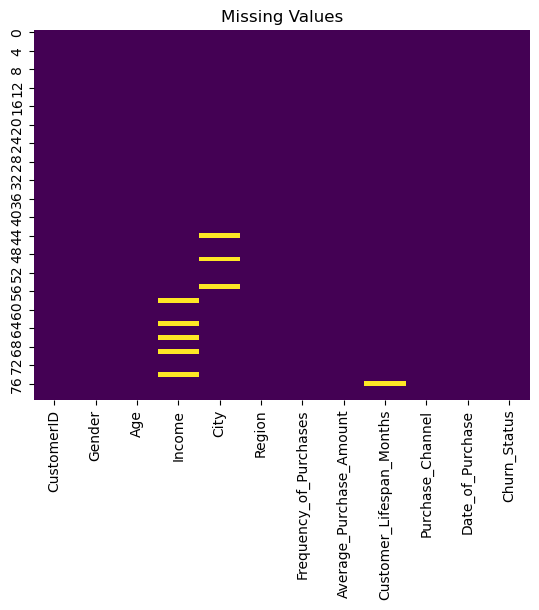

In [5]:
sns.heatmap(df.isnull(), cbar=False,  cmap='viridis')
plt.title('Missing Values')
plt.show()



In [6]:
# Numeric: median imputation (robust to outliers)
df['Income'] = df['Income'].fillna(df['Income'].median())
df['Customer_Lifespan_Months'] = df['Customer_Lifespan_Months'].fillna(df['Customer_Lifespan_Months'].median())

# Categorical: mode imputation
df['City'] = df['City'].fillna(df['City'].mode()[0])

df.isnull().sum()

CustomerID                  0
Gender                      0
Age                         0
Income                      0
City                        0
Region                      0
Frequency_of_Purchases      0
Average_Purchase_Amount     0
Customer_Lifespan_Months    0
Purchase_Channel            0
Date_of_Purchase            0
Churn_Status                0
dtype: int64

In [7]:
# Binary columns -> Label Encoding
le_gender = LabelEncoder()
df['Gender_encoded'] = le_gender.fit_transform(df['Gender'])                 # Male/Female -> 0/1

le_channel = LabelEncoder()
df['Purchase_Channel_encoded'] = le_channel.fit_transform(df['Purchase_Channel'])  # Online/In-store -> 0/1

le_churn = LabelEncoder()
df['Churn_Status_encoded'] = le_churn.fit_transform(df['Churn_Status'])     # No/Yes -> 0/1 (target)

# Nominal, multi-category -> One-Hot Encoding
df = pd.get_dummies(df, columns=['City', 'Region'], prefix=['City', 'Region'])

df.head()

,CustomerID,Gender,Age,Income,Frequency_of_Purchases,Average_Purchase_Amount,Customer_Lifespan_Months,Purchase_Channel,Date_of_Purchase,Churn_Status,Gender_encoded,Purchase_Channel_encoded,Churn_Status_encoded,City_Chicago,City_Houston,City_Los Angeles,City_New York,Region_Midwest,Region_Northeast,Region_West
0,C001,Male,49,72504.0,10,98.241,3.0,Online,2022-03-05,Yes,1,1,1,1,0,0,0,0,1,0
1,C002,Female,38,40881.0,15,157.640,4.0,In-store,2023-07-08,Yes,0,0,1,0,0,0,1,0,0,1
2,C003,Male,17,63333.0,1,41.252,1.0,Online,2023-01-30,No,1,1,0,0,0,0,1,0,1,0
3,C004,Male,34,58030.0,6,67.329,1.0,In-store,2023-06-01,No,1,0,0,1,0,0,0,1,0,0
4,C005,Male,30,78889.0,3,52.763,1.0,Online,2022-09-23,No,1,1,0,0,1,0,0,1,0,0


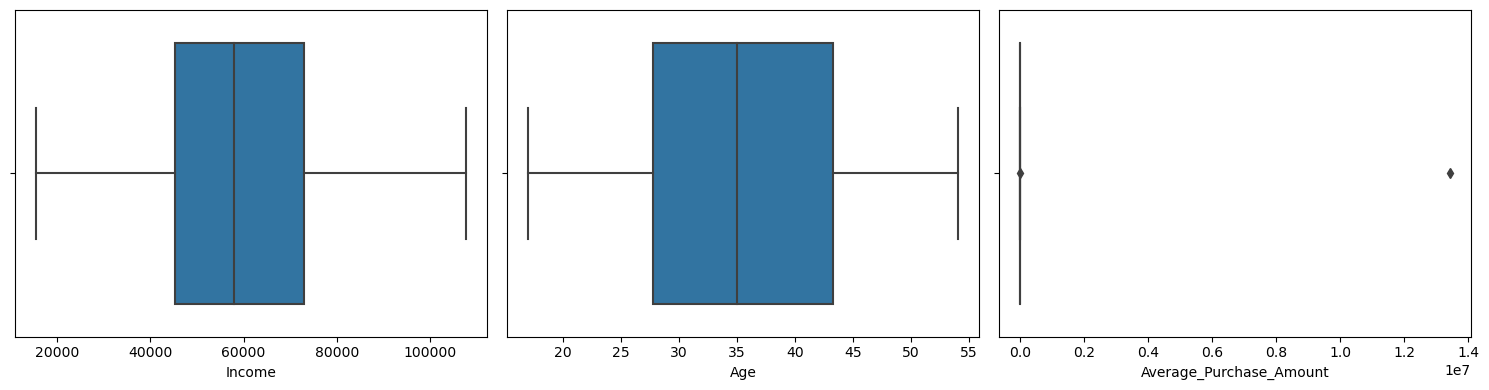

In [8]:
# Boxplots
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
sns.boxplot(x=df['Income'], ax=axes[0])
sns.boxplot(x=df['Age'], ax=axes[1])
sns.boxplot(x=df['Average_Purchase_Amount'], ax=axes[2])
plt.tight_layout()
plt.show()





In [9]:
# IQR method on Average_Purchase_Amount
Q1 = df['Income'].quantile(0.25)
Q3 = df['Income'].quantile(0.75)
IQR = Q3 - Q1
lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR

outliers = df[(df['Income'] < lower) | (df['Income'] > upper)]
print(f"Bounds: [{lower:.2f}, {upper:.2f}]")
print(f"Outliers found: {len(outliers)}")
outliers[['CustomerID', 'Income']]

Bounds: [3761.50, 114347.50]
Outliers found: 0


,CustomerID,Income


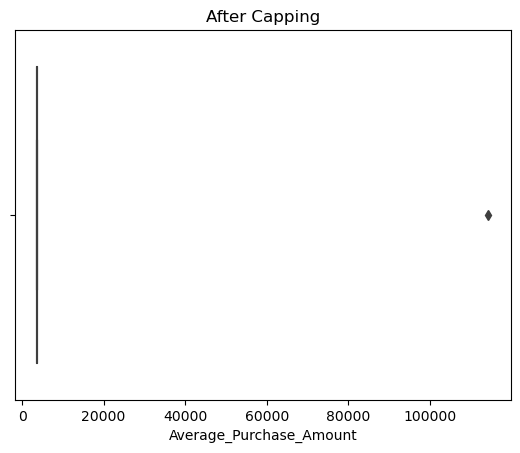

In [11]:
# Cap the extreme value(s) instead of dropping (winsorizing)
df['Average_Purchase_Amount'] = np.clip(df['Average_Purchase_Amount'], lower, upper)

sns.boxplot(x=df['Average_Purchase_Amount'])
plt.title('After Capping')
plt.show()

In [12]:
numeric_cols = ['Age', 'Income', 'Frequency_of_Purchases',
                 'Average_Purchase_Amount', 'Customer_Lifespan_Months']

scaler = RobustScaler()   # good choice here since we had outliers
df_scaled = df.copy()
df_scaled[numeric_cols] = scaler.fit_transform(df_scaled[numeric_cols])

df_scaled[numeric_cols].describe()

,Age,Income,Frequency_of_Purchases,Average_Purchase_Amount,Customer_Lifespan_Months
count,80.000000,80.000000,80.000000,80.000000,80.000000
mean,0.009677,0.045875,-0.072500,1382.325000,-0.512500
std,0.657866,0.694994,0.651187,12363.890668,0.954586
min,-1.161290,-1.537446,-1.700000,0.000000,-2.000000
25%,-0.467742,-0.463160,-0.500000,0.000000,-1.000000
50%,0.000000,0.000000,0.000000,0.000000,0.000000
75%,0.532258,0.536840,0.500000,0.000000,0.000000
max,1.225806,1.795019,1.300000,110586.000000,2.000000
